# NexaTel Customer Churn Analytics

## Phase 3 — Churn KPI Calculations

**Project:** NexaTel Customer Churn Analytics  
**Phase:** 3 — Churn KPI Calculations  
**Analyst:** Kashif Siddique  
**Tools:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook

### Objective

To calculate the business KPIs required by NexaTel management using the cleaned
Phase 1 datasets and the churn patterns identified during Phase 2.

The KPI calculations in this notebook focus on the **latest complete reporting
month: March 2026**, because the PRD defines churn as a monthly business metric
and the supplied customer/churn data runs through March 2026.

All KPI definitions are documented before calculation so that the results can
be reproduced and explained in a management or interview setting.

## Table of Contents

1. Environment Setup
2. Import Libraries
3. Load Phase 1 Cleaned Datasets
4. KPI Definitions and Reporting Assumptions
5. KPI Calculations
   - 5.1 Customer Churn Rate
   - 5.2 Customer Retention Rate
   - 5.3 ARPU
   - 5.4 Customer Lifetime Value
   - 5.5 Revenue Lost to Churn
   - 5.6 Monthly Recurring Revenue
   - 5.7 First Contact Resolution
   - 5.8 Average Resolution Time
   - 5.9 Contract Renewal Rate
   - 5.10 Average Customer Tenure
6. KPI Summary and Target Status
7. Monthly Churn / Retention Trend
8. Bonus — Cohort Retention Analysis
9. Management Insights
10. Phase 3 Conclusion
11. Phase 3 Requirement Checklist

## 1. Environment Setup

In [1]:
from pathlib import Path

required_tables = [
    "customers",
    "subscriptions",
    "plans",
    "support_tickets",
    "contracts",
]

candidate_clean_dirs = [
    Path("../data/cleaned"),
    Path("data/cleaned"),
    Path("/mnt/data/nexatel_phase3_final/cleaned"),
    Path("/mnt/data/nexatel_cleaned"),
]

clean_data_path = None

for candidate in candidate_clean_dirs:
    if all(
        (candidate / f"{table}_clean.csv").exists()
        for table in required_tables
    ):
        clean_data_path = candidate
        break

if clean_data_path is None:
    raise FileNotFoundError(
        "Phase 1 cleaned files were not found. "
        "Run Phase 1 first or place cleaned CSVs in ../data/cleaned/."
    )

if clean_data_path.name == "cleaned" and clean_data_path.parent.name == "data":
    project_root = clean_data_path.parent.parent
    output_path = project_root / "outputs" / "tables"
    chart_path = project_root / "outputs" / "charts"
else:
    output_path = Path("/mnt/data/nexatel_phase3_final/outputs")
    chart_path = output_path

output_path.mkdir(parents=True, exist_ok=True)
chart_path.mkdir(parents=True, exist_ok=True)

print("Clean data folder:", clean_data_path.resolve())
print("Output folder:", output_path.resolve())

Clean data folder: /mnt/data/nexatel_phase3_final/cleaned
Output folder: /mnt/data/nexatel_phase3_final/outputs


## 2. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

%matplotlib inline

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)

## 3. Load Phase 1 Cleaned Datasets

In [3]:
customers = pd.read_csv(
    clean_data_path / "customers_clean.csv",
    low_memory=False,
)

subscriptions = pd.read_csv(
    clean_data_path / "subscriptions_clean.csv",
    low_memory=False,
)

plans = pd.read_csv(
    clean_data_path / "plans_clean.csv",
    low_memory=False,
)

support_tickets = pd.read_csv(
    clean_data_path / "support_tickets_clean.csv",
    low_memory=False,
)

contracts = pd.read_csv(
    clean_data_path / "contracts_clean.csv",
    low_memory=False,
)

# Phase 1 exports dates in ISO format. This helper also accepts the
# original DD-MM-YYYY form so the notebook remains robust.
def parse_mixed_date(series):
    parsed = pd.to_datetime(
        series,
        format="%Y-%m-%d",
        errors="coerce",
    )

    remaining = parsed.isna() & series.notna()

    if remaining.any():
        parsed.loc[remaining] = pd.to_datetime(
            series.loc[remaining],
            format="%d-%m-%Y",
            errors="coerce",
        )

    return parsed

for column in [
    "acquisition_date",
    "churn_date",
]:
    customers[column] = parse_mixed_date(
        customers[column]
    )

for column in [
    "start_date",
    "end_date",
]:
    subscriptions[column] = parse_mixed_date(
        subscriptions[column]
    )

for column in [
    "created_date",
    "resolution_date",
]:
    support_tickets[column] = parse_mixed_date(
        support_tickets[column]
    )

for column in [
    "start_date",
    "end_date",
]:
    contracts[column] = parse_mixed_date(
        contracts[column]
    )

print("Phase 1 cleaned datasets loaded successfully.")

Phase 1 cleaned datasets loaded successfully.


### Dataset Verification

In [4]:
dataset_summary = pd.DataFrame([
    ["customers", len(customers), len(customers.columns)],
    ["subscriptions", len(subscriptions), len(subscriptions.columns)],
    ["plans", len(plans), len(plans.columns)],
    ["support_tickets", len(support_tickets), len(support_tickets.columns)],
    ["contracts", len(contracts), len(contracts.columns)],
], columns=["dataset", "rows", "columns"])

display(dataset_summary)

assert customers["customer_id"].is_unique
assert plans["plan_id"].is_unique

print("Core Phase 3 inputs validated.")

,dataset,rows,columns
0,customers,19000,25
1,subscriptions,20523,8
2,plans,25,10
3,support_tickets,31490,11
4,contracts,10607,9


Core Phase 3 inputs validated.


## 4. KPI Definitions and Reporting Assumptions

### Reporting Period

The latest complete month in the supplied churn data is **March 2026**.

- Reporting start: **01 March 2026**
- Reporting end: **31 March 2026**
- Customer churn and retention KPIs are therefore calculated for March 2026.

This is different from the Phase 2 **overall historical churn share**, which
measured all customers ever marked Churned. The Phase 3 churn KPI follows the
PRD's monthly formula.

### Active Subscriber Definition

For ARPU and MRR, an active subscriber is a **unique customer with at least one
subscription active at the reporting boundary**. Multiple active subscriptions
for the same customer contribute to recurring revenue, while the customer is
counted once in the subscriber denominator.

### CLV Gross-Margin Assumption

The provided NexaTel files and PRD do **not contain a gross-margin percentage**,
but the CLV formula requires one.

To complete the project calculation transparently, this notebook uses a
configurable **70% illustrative gross-margin assumption**:

`GROSS_MARGIN_PCT = 0.70`

This assumption is **not sourced from the NexaTel dataset**. In a real business
setting, it should be replaced with a finance-approved gross-margin figure.

In [5]:
REPORT_START = pd.Timestamp("2026-03-01")
REPORT_END = pd.Timestamp("2026-03-31")

GROSS_MARGIN_PCT = 0.70

print("Reporting month: March 2026")
print(f"Illustrative gross-margin assumption: {GROSS_MARGIN_PCT:.0%}")

Reporting month: March 2026
Illustrative gross-margin assumption: 70%


## 5. KPI Calculations

## 5.1 Customer Churn Rate

**Formula**

Customer Churn Rate = Customers Lost / Customers at Start × 100

The denominator is the customer base active at the start of March 2026. A
customer is considered active at the start if they were acquired before
01 March 2026 and had not churned before that date.

In [6]:
customers_at_start = int(
    (
        (customers["acquisition_date"] < REPORT_START)
        & (
            customers["churn_date"].isna()
            | (customers["churn_date"] >= REPORT_START)
        )
    ).sum()
)

customers_lost = int(
    (
        (customers["churn_date"] >= REPORT_START)
        & (customers["churn_date"] <= REPORT_END)
    ).sum()
)

customer_churn_rate = (
    customers_lost
    / customers_at_start
    * 100
)

print(f"Customers at start : {customers_at_start:,}")
print(f"Customers lost     : {customers_lost:,}")
print(f"Customer churn rate: {customer_churn_rate:.2f}%")

Customers at start : 15,688
Customers lost     : 198
Customer churn rate: 1.26%


### Observation

NexaTel lost **198 customers** from a starting base of
**15,688** during March 2026, producing a monthly churn rate of
**1.26%**. This is below the PRD target of **2.1%**, although
the monthly trend later in this notebook shows that churn increased from
February to March.

## 5.2 Customer Retention Rate

**Formula**

Customer Retention Rate = (Customers at End - New Customers) / Customers at Start × 100

In [7]:
new_customers = int(
    (
        (customers["acquisition_date"] >= REPORT_START)
        & (customers["acquisition_date"] <= REPORT_END)
    ).sum()
)

customers_at_end = int(
    (
        (customers["acquisition_date"] <= REPORT_END)
        & (
            customers["churn_date"].isna()
            | (customers["churn_date"] > REPORT_END)
        )
    ).sum()
)

customer_retention_rate = (
    (customers_at_end - new_customers)
    / customers_at_start
    * 100
)

print(f"Customers at end       : {customers_at_end:,}")
print(f"New customers          : {new_customers:,}")
print(f"Customer retention rate: {customer_retention_rate:.2f}%")

Customers at end       : 15,494
New customers          : 4
Customer retention rate: 98.74%


### Observation

The March 2026 retention rate is **98.74%** after removing
new customer additions from the ending base. Because only **4
new customers** were acquired in March, the retention rate is effectively the
positive mirror of the monthly churn result.

### 5.2.1 Prepare Active Subscription Base for Revenue KPIs

In [8]:
active_subscriptions_start = subscriptions[
    (subscriptions["start_date"] < REPORT_START)
    & (
        subscriptions["end_date"].isna()
        | (subscriptions["end_date"] >= REPORT_START)
    )
].copy()

active_subscriptions_end = subscriptions[
    (subscriptions["start_date"] <= REPORT_END)
    & (
        subscriptions["end_date"].isna()
        | (subscriptions["end_date"] > REPORT_END)
    )
].copy()

active_subscribers_start = (
    active_subscriptions_start["customer_id"]
    .nunique()
)

active_subscribers_end = (
    active_subscriptions_end["customer_id"]
    .nunique()
)

avg_active_subscribers = (
    active_subscribers_start
    + active_subscribers_end
) / 2

print(f"Active subscribers at start: {active_subscribers_start:,}")
print(f"Active subscribers at end  : {active_subscribers_end:,}")
print(f"Average active subscribers : {avg_active_subscribers:,.0f}")

Active subscribers at start: 15,913
Active subscribers at end  : 15,731
Average active subscribers : 15,822


## 5.3 ARPU — Average Revenue per User

**Formula**

ARPU = Total Recurring Revenue / Average Active Subscribers

For the March 2026 reporting month, total recurring revenue is represented by
the monthly recurring charges of subscriptions active at month end.

In [9]:
monthly_recurring_revenue = float(
    active_subscriptions_end[
        "monthly_charge_inr"
    ].sum()
)

arpu = (
    monthly_recurring_revenue
    / avg_active_subscribers
)

print(
    "Total recurring revenue:",
    f"₹{monthly_recurring_revenue:,.2f}",
)

print(
    "Average active subscribers:",
    f"{avg_active_subscribers:,.0f}",
)

print(
    "ARPU:",
    f"₹{arpu:,.2f}",
)

Total recurring revenue: ₹14,971,268.00
Average active subscribers: 15,822
ARPU: ₹946.23


### Observation

March 2026 ARPU is approximately **₹946.23 per active subscriber**. This
means NexaTel generated roughly ₹946 in monthly recurring revenue per
average active subscriber during the reporting month.

## 5.4 Customer Lifetime Value

**Formula**

Customer Lifetime Value = ARPU × Gross Margin % × (1 / Churn Rate)

The PRD requires gross margin in the formula, but no gross-margin field is
available in the supplied data. The calculation below therefore uses the
explicit 70% illustrative assumption defined earlier.

In [10]:
churn_rate_decimal = (
    customer_churn_rate / 100
)

customer_lifetime_value = (
    arpu
    * GROSS_MARGIN_PCT
    * (1 / churn_rate_decimal)
)

print(
    "Overall CLV scenario:",
    f"₹{customer_lifetime_value:,.2f}",
)

Overall CLV scenario: ₹52,480.46


### 5.4.1 CLV by Customer Segment

In [11]:
customer_segment_map = customers[
    ["customer_id", "customer_segment"]
]

active_start_segment = (
    active_subscriptions_start
    .merge(
        customer_segment_map,
        on="customer_id",
        how="left",
    )
)

active_end_segment = (
    active_subscriptions_end
    .merge(
        customer_segment_map,
        on="customer_id",
        how="left",
    )
)

segment_rows = []

for segment in sorted(
    customers["customer_segment"]
    .dropna()
    .unique()
):
    segment_customers = customers[
        customers["customer_segment"]
        .eq(segment)
    ]

    segment_start = int(
        (
            (
                segment_customers["acquisition_date"]
                < REPORT_START
            )
            & (
                segment_customers["churn_date"].isna()
                | (
                    segment_customers["churn_date"]
                    >= REPORT_START
                )
            )
        ).sum()
    )

    segment_lost = int(
        (
            (
                segment_customers["churn_date"]
                >= REPORT_START
            )
            & (
                segment_customers["churn_date"]
                <= REPORT_END
            )
        ).sum()
    )

    segment_churn = (
        segment_lost / segment_start
        if segment_start else np.nan
    )

    segment_mrr = float(
        active_end_segment.loc[
            active_end_segment[
                "customer_segment"
            ].eq(segment),
            "monthly_charge_inr",
        ].sum()
    )

    segment_avg_active = (
        active_start_segment.loc[
            active_start_segment[
                "customer_segment"
            ].eq(segment),
            "customer_id",
        ].nunique()
        + active_end_segment.loc[
            active_end_segment[
                "customer_segment"
            ].eq(segment),
            "customer_id",
        ].nunique()
    ) / 2

    segment_arpu = (
        segment_mrr / segment_avg_active
        if segment_avg_active else np.nan
    )

    segment_clv = (
        segment_arpu
        * GROSS_MARGIN_PCT
        * (1 / segment_churn)
        if segment_churn > 0 else np.nan
    )

    segment_rows.append({
        "customer_segment": segment,
        "customers_at_start": segment_start,
        "customers_lost": segment_lost,
        "churn_rate_pct": segment_churn * 100,
        "mrr_inr": segment_mrr,
        "avg_active_subscribers": segment_avg_active,
        "arpu_inr": segment_arpu,
        "clv_inr": segment_clv,
    })

segment_clv_summary = (
    pd.DataFrame(segment_rows)
    .sort_values(
        "clv_inr",
        ascending=False,
    )
)

display(
    segment_clv_summary.round(2)
)

,customer_segment,customers_at_start,customers_lost,churn_rate_pct,mrr_inr,avg_active_subscribers,arpu_inr,clv_inr
0,Enterprise,1237,13,1.05,5023321.0,1245.5,4033.18,268640.56
2,Premium,7264,67,0.92,6641081.0,7317.0,907.62,68881.85
3,Value,4982,63,1.26,2527138.0,5038.5,501.57,27764.44
1,Mass,2205,55,2.49,779728.0,2221.0,351.07,9852.32


### Observation

Using the 70% illustrative gross-margin assumption, overall CLV is approximately
**₹52,480.46**. Segment analysis shows **Premium CLV at about
₹68,882 versus ₹9,852 for Mass**, confirming the PRD's
expectation that higher-value segments should have substantially greater
lifetime value.

These CLV values are **scenario estimates** and will change if Finance provides
a different gross-margin percentage.

## 5.5 Revenue Lost to Churn

**Formula**

Revenue Lost to Churn = Churned Customers × Their ARPU

Rather than multiplying every churner by one overall ARPU, this notebook uses
each churned customer's active recurring subscription charges at the date of
churn. The sum is therefore the monthly recurring revenue actually associated
with customers lost during March.

In [12]:
march_churners = customers.loc[
    (
        customers["churn_date"]
        >= REPORT_START
    )
    & (
        customers["churn_date"]
        <= REPORT_END
    ),
    [
        "customer_id",
        "churn_date",
    ],
]

churner_subscriptions = march_churners.merge(
    subscriptions[
        [
            "customer_id",
            "start_date",
            "end_date",
            "monthly_charge_inr",
        ]
    ],
    on="customer_id",
    how="left",
)

active_at_churn = churner_subscriptions[
    (
        churner_subscriptions["start_date"]
        <= churner_subscriptions["churn_date"]
    )
    & (
        churner_subscriptions["end_date"].isna()
        | (
            churner_subscriptions["end_date"]
            >= churner_subscriptions["churn_date"]
        )
    )
]

revenue_lost_to_churn = float(
    active_at_churn[
        "monthly_charge_inr"
    ].sum()
)

avg_churner_arpu = (
    revenue_lost_to_churn
    / len(march_churners)
)

print(
    "March churned customers:",
    f"{len(march_churners):,}",
)

print(
    "Average recurring revenue per churner:",
    f"₹{avg_churner_arpu:,.2f}",
)

print(
    "Monthly recurring revenue lost to churn:",
    f"₹{revenue_lost_to_churn:,.2f}",
)

March churned customers: 198
Average recurring revenue per churner: ₹696.78
Monthly recurring revenue lost to churn: ₹137,963.00


### Observation

The **198 customers lost in March** represented approximately
**₹137,963.00 in monthly recurring revenue**, with an average of about
**₹696.78 per churned customer**. This converts the churn KPI
into a direct monthly revenue-at-risk measure.

## 5.6 Monthly Recurring Revenue

**Formula**

Monthly Recurring Revenue = Sum of Active Recurring Charges

In [13]:
mrr = float(
    active_subscriptions_end[
        "monthly_charge_inr"
    ].sum()
)

print(
    "March 2026 MRR:",
    f"₹{mrr:,.2f}",
)

March 2026 MRR: ₹14,971,268.00


### Observation

NexaTel's March 2026 monthly recurring revenue is approximately
**₹14,971,268** from subscriptions active at month end. This represents the
predictable recurring revenue base available before considering one-off
recharges, device sales, or other non-recurring income.

## 5.7 First Contact Resolution

**Formula**

First Contact Resolution = Resolved on First Contact / Total Tickets × 100

PRD target: **greater than 78%**

In [14]:
fcr_yes = int(
    support_tickets[
        "first_contact_resolution"
    ].eq("Yes").sum()
)

total_tickets = len(
    support_tickets
)

first_contact_resolution_rate = (
    fcr_yes
    / total_tickets
    * 100
)

print(
    "Resolved on first contact:",
    f"{fcr_yes:,}",
)
print(
    "Total support tickets:",
    f"{total_tickets:,}",
)
print(
    "FCR rate:",
    f"{first_contact_resolution_rate:.2f}%",
)

Resolved on first contact: 12,726
Total support tickets: 31,490
FCR rate: 40.41%


### Observation

First Contact Resolution is only **40.41%**, well below the PRD target of
**78%**. This is one of the most concerning Phase 3 service KPIs and aligns with
the Phase 2 finding that unresolved service issues are strongly associated with
higher churn.

## 5.8 Average Resolution Time

**Formula**

Average Resolution Time = Mean Resolution Hours

PRD target: **less than 24 hours**

`resolution_hours` is populated only for resolved tickets, so the mean naturally
uses resolved cases with valid resolution duration.

In [15]:
resolved_resolution_hours = (
    support_tickets[
        "resolution_hours"
    ].dropna()
)

avg_resolution_time = float(
    resolved_resolution_hours.mean()
)

print(
    "Resolved tickets with resolution hours:",
    f"{len(resolved_resolution_hours):,}",
)
print(
    "Average resolution time:",
    f"{avg_resolution_time:.2f} hours",
)

Resolved tickets with resolution hours: 18,124
Average resolution time: 16.04 hours


### Observation

Average resolution time is **16.04 hours**, which meets the
PRD target of **under 24 hours**. However, the strong result on resolution speed
does not offset the weak FCR rate, suggesting that NexaTel resolves many tickets
within target time but often requires more than one customer interaction.

## 5.9 Contract Renewal Rate

**Formula**

Contract Renewal Rate = Contracts Renewed / Contracts Due for Renewal × 100

PRD target: **greater than 88%**

A contract is treated as **due for renewal** when its documented `end_date` is
on or before 31 March 2026. Renewed and Auto-Renewed statuses count in the
numerator. Other statuses remain in the due denominator.

In [16]:
contracts_due = contracts[
    contracts["end_date"]
    <= REPORT_END
].copy()

contracts_renewed = int(
    contracts_due[
        "renewal_status"
    ]
    .isin([
        "Renewed",
        "Auto-Renewed",
    ])
    .sum()
)

contract_renewal_rate = (
    contracts_renewed
    / len(contracts_due)
    * 100
)

print(
    "Contracts due for renewal:",
    f"{len(contracts_due):,}",
)
print(
    "Renewed / Auto-Renewed:",
    f"{contracts_renewed:,}",
)
print(
    "Contract renewal rate:",
    f"{contract_renewal_rate:.2f}%",
)

print("\nDue-contract status distribution:")
display(
    contracts_due[
        "renewal_status"
    ]
    .value_counts(dropna=False)
    .rename("contracts")
    .to_frame()
)

Contracts due for renewal: 9,651
Renewed / Auto-Renewed: 5,516
Contract renewal rate: 57.15%

Due-contract status distribution:


,contracts
renewal_status,
Renewed,3421
Auto-Renewed,2095
Active,1683
Pending,1264
Not Renewed,846
Cancelled,342


### Observation

The contract renewal rate is **57.15%**, substantially
below the PRD target of **88%**. Contract retention therefore represents another
major opportunity, particularly for postpaid, fibre, and enterprise customers
where renewal behaviour directly protects recurring revenue.

## 5.10 Average Customer Tenure

**Formula**

Average Customer Tenure = Mean tenure_months of Active Customer Base

In [17]:
active_customer_base = customers[
    customers["customer_status"]
    .eq("Active")
]

avg_customer_tenure = float(
    active_customer_base[
        "tenure_months"
    ].mean()
)

print(
    "Active customers:",
    f"{len(active_customer_base):,}",
)

print(
    "Average active-customer tenure:",
    f"{avg_customer_tenure:.2f} months",
)

print(
    "Average active-customer tenure:",
    f"{avg_customer_tenure / 12:.2f} years",
)

Active customers: 15,494
Average active-customer tenure: 87.08 months
Average active-customer tenure: 7.26 years


### Observation

The active customer base has an average tenure of **87.08
months**, or roughly **7.26 years**. This relatively long
average tenure contrasts with the very high churn observed among new customers
in Phase 2, reinforcing the importance of improving early-life retention.

## 6. KPI Summary and Target Status

In [18]:
kpi_summary = pd.DataFrame([
    [
        "Customer Churn Rate",
        customer_churn_rate,
        "%",
        "< 2.1%",
        "MEETS TARGET" if customer_churn_rate < 2.1 else "BELOW TARGET",
    ],
    [
        "Customer Retention Rate",
        customer_retention_rate,
        "%",
        "No PRD target",
        "REFERENCE",
    ],
    [
        "ARPU",
        arpu,
        "INR / subscriber / month",
        "No PRD target",
        "REFERENCE",
    ],
    [
        "Customer Lifetime Value",
        customer_lifetime_value,
        "INR (70% margin scenario)",
        "No numeric PRD target",
        "REFERENCE",
    ],
    [
        "Revenue Lost to Churn",
        revenue_lost_to_churn,
        "INR monthly recurring revenue",
        "No PRD target",
        "RISK METRIC",
    ],
    [
        "Monthly Recurring Revenue",
        mrr,
        "INR / month",
        "No PRD target",
        "REFERENCE",
    ],
    [
        "First Contact Resolution",
        first_contact_resolution_rate,
        "%",
        "> 78%",
        "MEETS TARGET" if first_contact_resolution_rate > 78 else "BELOW TARGET",
    ],
    [
        "Average Resolution Time",
        avg_resolution_time,
        "hours",
        "< 24h",
        "MEETS TARGET" if avg_resolution_time < 24 else "BELOW TARGET",
    ],
    [
        "Contract Renewal Rate",
        contract_renewal_rate,
        "%",
        "> 88%",
        "MEETS TARGET" if contract_renewal_rate > 88 else "BELOW TARGET",
    ],
    [
        "Average Customer Tenure",
        avg_customer_tenure,
        "months",
        "No PRD target",
        "REFERENCE",
    ],
], columns=[
    "KPI",
    "Value",
    "Unit",
    "PRD Target",
    "Status",
])

display(
    kpi_summary.round(2)
)

,KPI,Value,Unit,PRD Target,Status
0,Customer Churn Rate,1.26,%,< 2.1%,MEETS TARGET
1,Customer Retention Rate,98.74,%,No PRD target,REFERENCE
2,ARPU,946.23,INR / subscriber / month,No PRD target,REFERENCE
3,Customer Lifetime Value,52480.46,INR (70% margin scenario),No numeric PRD target,REFERENCE
4,Revenue Lost to Churn,137963.00,INR monthly recurring revenue,No PRD target,RISK METRIC
5,Monthly Recurring Revenue,14971268.00,INR / month,No PRD target,REFERENCE
6,First Contact Resolution,40.41,%,> 78%,BELOW TARGET
7,Average Resolution Time,16.04,hours,< 24h,MEETS TARGET
8,Contract Renewal Rate,57.15,%,> 88%,BELOW TARGET
9,Average Customer Tenure,87.08,months,No PRD target,REFERENCE


### KPI Summary Interpretation

Three PRD metrics have explicit numerical targets:

- **Monthly churn: 1.26% — meets the <2.1% target**
- **FCR: 40.41% — well below the >78% target**
- **Average resolution time: 16.04 hours — meets the <24h target**
- **Contract renewal: 57.15% — well below the >88% target**

The combination suggests that NexaTel's immediate service challenge is not
primarily the speed of closing resolved tickets; it is the low probability of
solving issues on the first interaction and the weak conversion of due
contracts into renewals.

## 7. Monthly Churn / Retention Trend

In [19]:
monthly_rows = []

for period in pd.period_range(
    "2025-04",
    "2026-03",
    freq="M",
):
    month_start = period.start_time
    month_end = period.end_time.normalize()

    start_count = int(
        (
            (customers["acquisition_date"] < month_start)
            & (
                customers["churn_date"].isna()
                | (
                    customers["churn_date"]
                    >= month_start
                )
            )
        ).sum()
    )

    lost_count = int(
        (
            (
                customers["churn_date"]
                >= month_start
            )
            & (
                customers["churn_date"]
                <= month_end
            )
        ).sum()
    )

    new_count = int(
        (
            (
                customers["acquisition_date"]
                >= month_start
            )
            & (
                customers["acquisition_date"]
                <= month_end
            )
        ).sum()
    )

    end_count = int(
        (
            (
                customers["acquisition_date"]
                <= month_end
            )
            & (
                customers["churn_date"].isna()
                | (
                    customers["churn_date"]
                    > month_end
                )
            )
        ).sum()
    )

    churn_pct = (
        lost_count
        / start_count
        * 100
    )

    retention_pct = (
        (end_count - new_count)
        / start_count
        * 100
    )

    monthly_rows.append({
        "month": str(period),
        "customers_at_start": start_count,
        "customers_lost": lost_count,
        "new_customers": new_count,
        "customers_at_end": end_count,
        "churn_rate_pct": churn_pct,
        "retention_rate_pct": retention_pct,
    })

monthly_kpi_trend = pd.DataFrame(
    monthly_rows
)

display(
    monthly_kpi_trend.round(2)
)

,month,customers_at_start,customers_lost,new_customers,customers_at_end,churn_rate_pct,retention_rate_pct
0,2025-04,15515,68,99,15546,0.44,99.56
1,2025-05,15546,63,113,15596,0.41,99.59
2,2025-06,15596,77,108,15627,0.49,99.51
3,2025-07,15627,91,125,15661,0.58,99.42
4,2025-08,15661,102,125,15684,0.65,99.35
5,2025-09,15684,83,113,15714,0.53,99.47
6,2025-10,15714,94,135,15755,0.60,99.40
7,2025-11,15755,113,113,15755,0.72,99.28
8,2025-12,15755,109,106,15752,0.69,99.31
9,2026-01,15752,124,113,15741,0.79,99.21


### Trend Observation

Monthly churn remained below the **2.1% PRD target** throughout the latest
12-month period, but it increased from **0.91% in
February 2026** to **1.26% in March
2026**. The latest result therefore meets the target while still showing a
short-term deterioration that management should monitor.

## 8. Bonus — Cohort Retention Analysis

The optional cohort analysis groups customers by acquisition month and measures
the share still retained after **3, 6, and 12 months**.

A customer is counted as retained at a milestone when they have not churned
before that milestone. Cohorts that are too recent to have reached a milestone
are excluded from that milestone's denominator.

In [20]:
cohort_source = customers[
    [
        "customer_id",
        "acquisition_date",
        "churn_date",
    ]
].copy()

cohort_source["cohort_month"] = (
    cohort_source["acquisition_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

cohort_tables = []

for horizon in [3, 6, 12]:
    milestone = (
        cohort_source["acquisition_date"]
        + pd.DateOffset(months=horizon)
    )

    eligible = milestone <= REPORT_END

    retained = (
        cohort_source["churn_date"].isna()
        | (
            cohort_source["churn_date"]
            >= milestone
        )
    )

    horizon_data = cohort_source.loc[
        eligible,
        ["cohort_month"],
    ].copy()

    horizon_data[
        f"retained_{horizon}m"
    ] = (
        retained.loc[eligible]
        .astype(int)
        .values
    )

    retention = (
        horizon_data
        .groupby("cohort_month")[
            f"retained_{horizon}m"
        ]
        .mean()
        .mul(100)
        .rename(f"{horizon}m")
    )

    cohort_tables.append(retention)

cohort_retention = (
    pd.concat(
        cohort_tables,
        axis=1,
    )
    .sort_index()
)

display(
    cohort_retention
    .tail(24)
    .round(2)
)

,3m,6m,12m
cohort_month,,,
2024-01-01,96.43,93.75,82.14
2024-02-01,97.25,89.91,81.65
2024-03-01,98.08,92.31,85.58
2024-04-01,94.83,87.07,78.45
2024-05-01,97.44,90.60,84.62
2024-06-01,97.27,92.73,82.73
2024-07-01,93.02,89.92,83.72
2024-08-01,96.77,91.13,81.45
2024-09-01,93.04,87.83,76.52


### 8.1 Cohort Retention Pattern

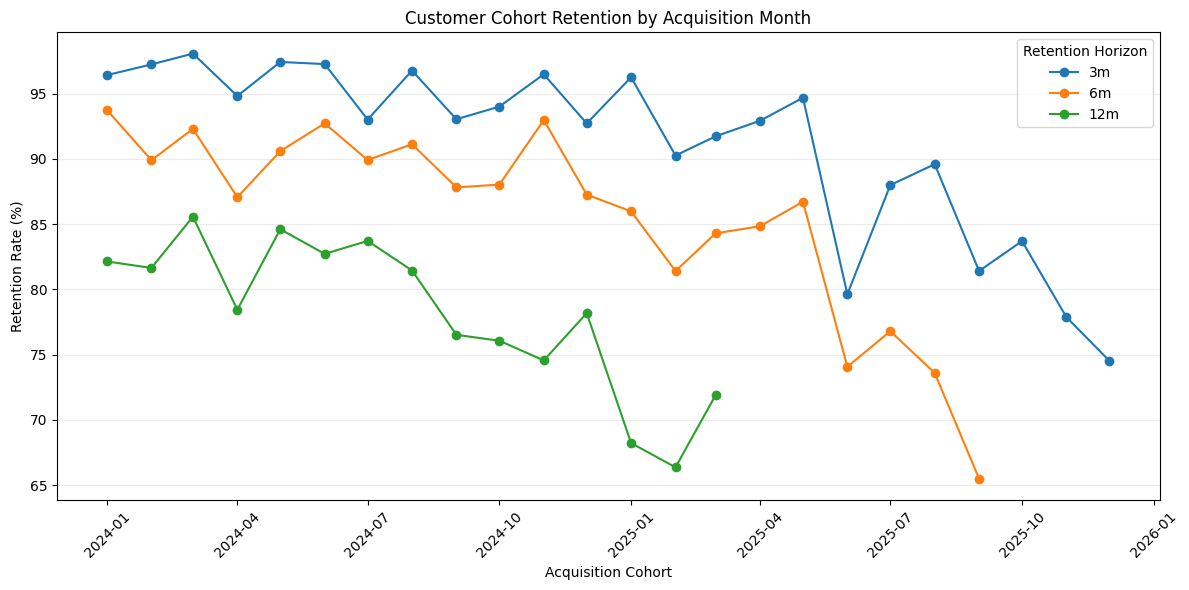

Saved: /mnt/data/nexatel_phase3_final/outputs/Phase3_Bonus_Cohort_Retention.png


In [21]:
plot_cohorts = cohort_retention[
    cohort_retention.index
    >= pd.Timestamp("2024-01-01")
].copy()

fig, ax = plt.subplots(
    figsize=(12, 6)
)

for column in [
    "3m",
    "6m",
    "12m",
]:
    ax.plot(
        plot_cohorts.index,
        plot_cohorts[column],
        marker="o",
        label=column,
    )

ax.set_title(
    "Customer Cohort Retention by Acquisition Month"
)
ax.set_xlabel(
    "Acquisition Cohort"
)
ax.set_ylabel(
    "Retention Rate (%)"
)
ax.legend(
    title="Retention Horizon"
)
ax.grid(
    axis="y",
    alpha=0.25,
)

plt.xticks(
    rotation=45
)
plt.tight_layout()

cohort_chart = (
    chart_path
    / "Phase3_Bonus_Cohort_Retention.png"
)

plt.savefig(
    cohort_chart,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    cohort_chart,
)

### Cohort Observation

The cohort table shows the expected decline between 3-, 6-, and 12-month
retention as customers have more time to churn. More recent cohorts have blank
12-month values because they have not yet had enough observation time, which is
why the analysis uses milestone eligibility rather than treating those rows as
zero retention.

This bonus analysis will be useful later when management wants to distinguish
whether retention is improving for newer acquisition cohorts.

## 9. Management Insights

The Phase 3 KPI calculations highlight four important management messages:

1. **Monthly churn currently meets target but is worsening.**  
   March churn is **1.26%**, below the 2.1% target, but it
   rose from **0.91% in February**.
   This means the headline KPI is healthy on target status but moving in the
   wrong short-term direction.

2. **First Contact Resolution is the clearest service weakness.**  
   FCR is only **40.41%** versus a target above 78%, even though average
   resolution time is a healthy **16.04 hours**. NexaTel
   appears to close many resolved cases quickly, but too few are solved during
   the first interaction.

3. **Contract renewal performance is substantially below target.**  
   The renewal rate is **57.15%**, far below the required
   88%. This creates a recurring-revenue retention risk, particularly for
   contract-led product lines.

4. **Churn has a measurable revenue impact.**  
   March churn removed approximately **₹137,963 of monthly recurring
   revenue**, while total MRR was about **₹14,971,268**. Preventing churn among
   higher-ARPU customers can therefore protect meaningful recurring revenue.

The CLV scenario also reinforces the value of prioritizing higher-value
segments: Premium CLV is approximately **₹68,882**, substantially
above the Mass segment under the same margin assumption.

## 10. Phase 3 Conclusion

Phase 3 — Churn KPI Calculations was completed using the cleaned NexaTel
datasets and a March 2026 reporting period.

All **10 required business KPIs** were calculated and clearly documented.
March monthly churn is **1.26%**, customer retention is
**98.74%**, ARPU is approximately **₹946.23**, MRR
is approximately **₹14,971,268**, and monthly recurring revenue lost to churn is
approximately **₹137,963**.

Operationally, average resolution time meets target, while First Contact
Resolution and contract renewal are substantially below their PRD targets.
These two KPIs represent the clearest management improvement opportunities
identified in Phase 3.

The optional cohort retention analysis has also been completed, providing an
additional view of customer stickiness by acquisition month.

**Phase 3 Status: COMPLETE ✅**

## 11. Export KPI Outputs

In [22]:
kpi_summary.to_csv(
    output_path
    / "Phase3_KPI_Summary_KashifSiddique.csv",
    index=False,
)

segment_clv_summary.to_csv(
    output_path
    / "Phase3_Segment_CLV_KashifSiddique.csv",
    index=False,
)

monthly_kpi_trend.to_csv(
    output_path
    / "Phase3_Monthly_Churn_Retention_Trend.csv",
    index=False,
)

cohort_retention.to_csv(
    output_path
    / "Phase3_Cohort_Retention_KashifSiddique.csv"
)

print("Phase 3 supporting outputs exported successfully.")

Phase 3 supporting outputs exported successfully.


## 12. Phase 3 Requirement Checklist

In [23]:
phase3_checklist = pd.DataFrame([
    ["Customer Churn Rate", "COMPLETE"],
    ["Customer Retention Rate", "COMPLETE"],
    ["ARPU", "COMPLETE"],
    ["Customer Lifetime Value", "COMPLETE"],
    ["Revenue Lost to Churn", "COMPLETE"],
    ["Monthly Recurring Revenue", "COMPLETE"],
    ["First Contact Resolution", "COMPLETE"],
    ["Average Resolution Time", "COMPLETE"],
    ["Contract Renewal Rate", "COMPLETE"],
    ["Average Customer Tenure", "COMPLETE"],
    ["All KPI formulas clearly labelled", "COMPLETE"],
    ["KPI summary and target status", "COMPLETE"],
    ["Bonus cohort retention analysis", "COMPLETE"],
    ["Cohort retention pattern visible", "COMPLETE"],
    ["Supporting KPI tables exported", "COMPLETE"],
], columns=[
    "Phase 3 Requirement",
    "Status",
])

display(
    phase3_checklist
)

,Phase 3 Requirement,Status
0,Customer Churn Rate,COMPLETE
1,Customer Retention Rate,COMPLETE
2,ARPU,COMPLETE
3,Customer Lifetime Value,COMPLETE
4,Revenue Lost to Churn,COMPLETE
5,Monthly Recurring Revenue,COMPLETE
6,First Contact Resolution,COMPLETE
7,Average Resolution Time,COMPLETE
8,Contract Renewal Rate,COMPLETE
9,Average Customer Tenure,COMPLETE


## Phase 3 Completion Status

**PHASE 3 — COMPLETE ✅**

The notebook contains all 10 required KPI calculations, clearly documents the
reporting definitions and assumptions, compares target-based KPIs against the
PRD thresholds, and includes the optional cohort retention analysis.